In [2]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.collections import LineCollection
from scipy.ndimage import gaussian_filter1d

In [6]:
# loading data
data = np.load('/home/hck03/Documents/MS_thesis/tracking_output/1c_4n_faulty/Clip0042_1C_4N_E4_10/data/clean_tracks.npy')
print(data.shape)

(5, 1882, 2)


In [7]:
# finding kinematic variables
## distance-time variables
dt = 0.01
vel = np.gradient(data, axis=1)/dt
speed = np.linalg.norm(vel, axis=2)
acc_mag = np.gradient(speed, axis=1)

## manoeuvrability variables
theta = np.arctan2(vel[..., 1], vel[..., 0])


def wrap(d):
    return (d + np.pi) % (2*np.pi) - np.pi

# w = 14
# d1 = wrap(theta[:, 1:] - theta[:, :-1])           
# U = np.concatenate([np.zeros((theta.shape[0], 1)),
#                     np.nancumsum(d1, axis=1)], axis=1)  
# omega = (U[:, w:] - U[:, :-w]) / (w * dt) 

# w = 14
# simple = wrap(theta[:, w:] - theta[:, :-w])
# d1 = wrap(theta[:, 1:] - theta[:, :-1])
# U = np.concatenate([np.zeros((theta.shape[0], 1)), np.cumsum(d1, axis=1)], axis=1)
# careful = U[:, w:] - U[:, :-w]

dtheta = theta[:, 2:] - theta[:, :-2]
dtheta = (dtheta + np.pi) % (2*np.pi) - np.pi 
dtheta = np.degrees(dtheta)
omega = np.full_like(theta, np.nan)
omega[:, 1:-1] = dtheta / (2*dt)

alpha = np.gradient(omega, axis=1)

alpha_smooth = gaussian_filter1d(alpha, sigma=3)
omega_smooth = gaussian_filter1d(omega, sigma=3)


In [11]:
# finding sigma
sig = np.arange(0.5, 5, 0.5)

# def autocorr(original, smooth, max_t_lag=20):
#     residues = original - smooth
#     res_normalized = (residues - np.mean(residues)) / np.std(residues)

#     autocorrealtion = []
#     for tau in range(max_t_lag):
#         if tau == 0:
#             c = np.mean(res_normalized*res_normalized)
#         else:
#             c = np.mean(res_normalized[:-tau] * res_normalized[tau:])
#         autocorrealtion.append(c)
#     return np.array(autocorrealtion)

for sigma in sig:
    N = len(speed)
    speed_smooth_i = gaussian_filter1d(speed, sigma=sigma)
    residues = speed - speed_smooth_i
    res_centered = residues - np.mean(residues)

    numerator = np.sum(res_centered[:-1] * res_centered[1:])
    denominator = np.sum(res_centered**2)
    r1 = numerator / denominator
    threshold = 1.96 / np.sqrt(N)

    if r1 > threshold:
        print(f'for sigma = {sigma} the curve is oversmoothed')
    else:
        print(f'for sigma = {sigma} the curve is smoothed well')
    # auto correlation on residues
    # acf = autocorr(speed, speed_smooth_i)



for sigma = 0.5 the curve is smoothed well
for sigma = 1.0 the curve is smoothed well
for sigma = 1.5 the curve is smoothed well
for sigma = 2.0 the curve is smoothed well
for sigma = 2.5 the curve is smoothed well
for sigma = 3.0 the curve is smoothed well
for sigma = 3.5 the curve is smoothed well
for sigma = 4.0 the curve is smoothed well
for sigma = 4.5 the curve is smoothed well


In [31]:
omega_smooth.shape

(5, 1882)

In [35]:
light_on_frame = 55
t = 300
end_time = light_on_frame + t

NameError: name 'light_on_frame' is not defined

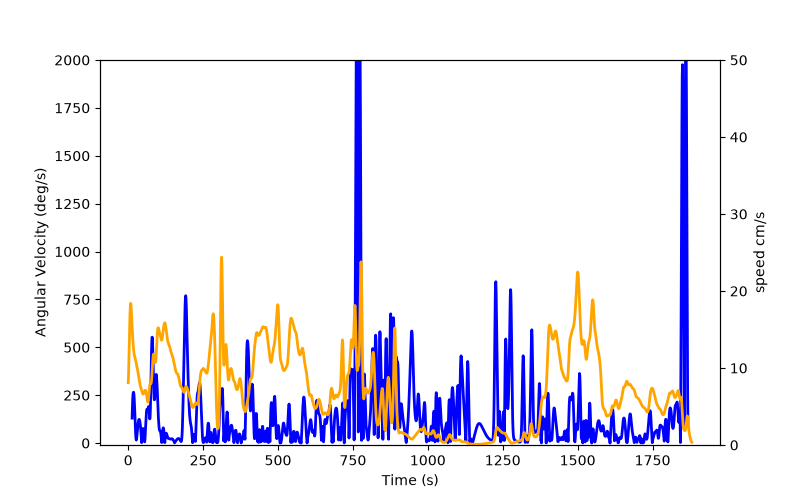

In [12]:
plt.close()
id = 3
x = np.arange(omega.shape[1])
y1 = np.abs(omega_smooth[id,:])
y2 = gaussian_filter1d(speed[id,:], sigma=3)

fig, ax1 = plt.subplots(figsize=(8, 5))
color1 = 'blue'
ax1.set_xlabel('Time (s)')
ax1.set_ylabel('Angular Velocity (deg/s)')
ax1.plot(x, y1, color=color1, linewidth=2, label='Velocity')
ax1.tick_params(axis='y')
# ax1.set_xlim(58, 102)
ax1.set_ylim(bottom=0)
ax1.set_ylim(-10, 2000)

ax2 = ax1.twinx()

color2 = 'orange'
ax2.set_ylabel('speed cm/s')
ax2.plot(x, y2, color=color2, linewidth=2, label='speed')
ax2.tick_params(axis='y')
ax2.set_ylim(-10, 50)
ax2.set_ylim(bottom=0)
plt.axvline(x=light_on_frame, color='r', linestyle='--')
plt.axvline(x=end_time, color='r', linestyle='--')
plt.axhline(y=0.0, color='k', linestyle='--', alpha=0.5)


fig.tight_layout()
plt.show()

In [14]:
# plt.close()
# id = 1
# x = np.arange(omega.shape[1])
# y1 = np.abs(np.gradient(omega_smooth[id,:]))
# y2 = np.abs(np.gradient(speed[id,:]))

# fig, ax1 = plt.subplots(figsize=(8, 5))
# color1 = 'blue'
# ax1.set_xlabel('Time (s)')
# ax1.set_ylabel('Angular Velocity (deg/s)')
# ax1.plot(x, y1, color=color1, linewidth=2, label='Velocity')
# ax1.tick_params(axis='y')
# ax1.set_xlim(light_on_frame-50, end_time+50)
# ax1.set_ylim(bottom=0)
# # ax1.set_ylim(-10, 2000)

# ax2 = ax1.twinx()

# color2 = 'orange'
# ax2.set_ylabel('speed cm/s')
# ax2.plot(x, y2, color=color2, linewidth=2, label='speed')
# ax2.tick_params(axis='y')
# # ax2.set_ylim(-10, 50)
# ax2.set_ylim(bottom=0)
# plt.axvline(x=light_on_frame, color='r', linestyle='--')
# plt.axvline(x=end_time, color='r', linestyle='--')
# plt.axhline(y=0.0, color='k', linestyle='--', alpha=0.5)


# fig.tight_layout()
# plt.show()

In [ ]:
r_start = 58
r_end = 102

omega_r_window = y1[r_start:r_end+1]
speed_r_window = y2[r_start:r_end+1]

max_r_omega = np.max(omega_r_window)
max_r_speed = np.max(speed_r_window)

In [54]:
max_r_omega

np.float64(553.0807909906272)

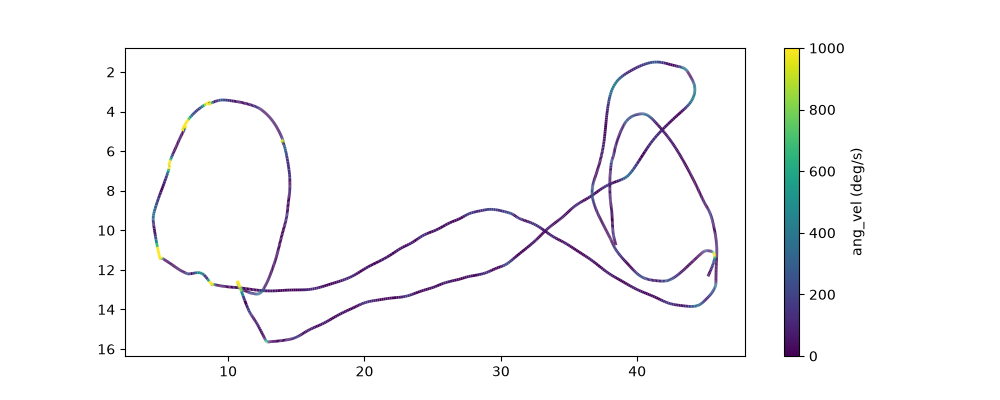

In [37]:
l = 10
import matplotlib.colors as mcolors
plt.close()
fig, ax = plt.subplots(figsize = (l, l*(20/50)))
x = gaussian_filter1d(data[id,:,0], sigma=2)
y = gaussian_filter1d(data[id,:,1], sigma=2)
ang_v = np.abs(omega_smooth[id,:])
segment_speeds = ang_v[:-1]
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

norm = mcolors.Normalize(vmin=0, vmax=1000)
lc = LineCollection(segments, cmap='viridis', norm=norm)
lc.set_array(segment_speeds)
lc.set_linewidth(2)
line = ax.add_collection(lc)

fig.colorbar(line, ax=ax, label='ang_vel (deg/s)')
ax.autoscale()
ax.invert_yaxis()
plt.show()


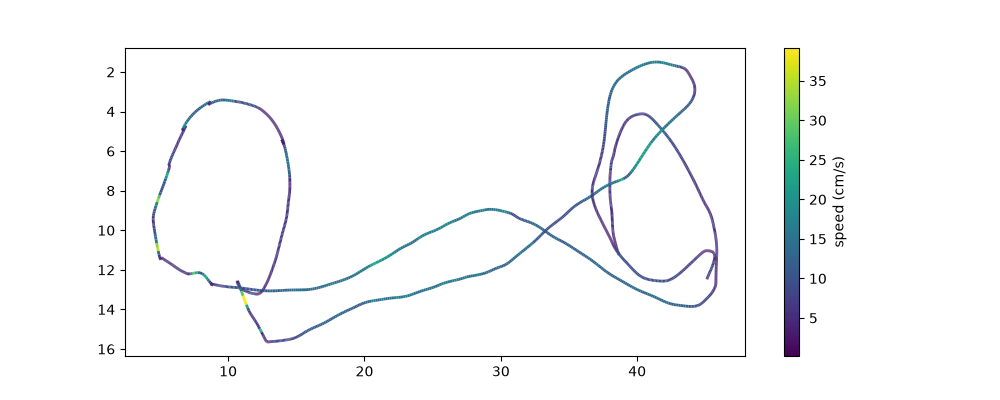

In [38]:
l = 10
plt.close()
fig, ax = plt.subplots(figsize = (l, l*(20/50)))
x = gaussian_filter1d(data[id,:,0], sigma=2)
y = gaussian_filter1d(data[id,:,1], sigma=2)
ang_v = speed[id,:]
segment_speeds = ang_v[:-1]
points = np.array([x, y]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

lc = LineCollection(segments, cmap='viridis')
lc.set_array(segment_speeds)
lc.set_linewidth(2)
line = ax.add_collection(lc)

fig.colorbar(line, ax=ax, label='speed (cm/s)')
ax.autoscale()
ax.invert_yaxis()
plt.show()

In [10]:
# from pathlib import Path
# import numpy as np
# filepath = Path('/home/hck03/Documents/MS_thesis/tracking_output/1c_4n_faulty/Clip0079_E7_1/data/grand_array.npy')
# parent_dir = filepath.resolve().parent

# data = np.load(filepath)

# save_path = parent_dir / 'grand_array_2.npy'
# data[[0, 1], 319:, :] = data[[1, 0], 319:, :]

# np.save(save_path, data)


In [11]:
# identifying conditioned
search_time = np.arange(light_on_frame, end_time)
# so we will find peaks in angular velocity and speed and based on that we will decide. We need to set a threshold also how do we do that?
# need to think about that


In [ ]:
file_names = [
    "Clip0001_1C_4N_G_1",
    "Clip0003_1C_4N_G_3",
    "Clip0006_1C_4N_G_6",
    "Clip0009_1C_4N_G_8",
    "Clip0010_1C_4N_G_9",
    "Clip0011_1C_4N_G_10",
    "Clip0017_1C_4N_T_6",
    "Clip0020_1C_4N_T_8",
    "Clip0021_1C_4N_T_9",
    "Clip0022_1C_4N_T_10",
    "Clip0023_1C_4N_E2_1",
    "Clip0042_1C_4N_E4_10",
    "Clip0049_1C_4N_E9_7",
    "Clip0050_1C_4N_E9_8",
    "Clip0058_1C_4N_E7_6",
    "Clip0070_1C_4N_E3_8",
    "Clip0074_1C_4N_E8_1",
    "Clip0078_1C_4N_E8_5",
    "Clip0079_1C_4N_E8_6",
    "Clip0079_E7_1",
    "Clip0080_1C_4N_E8_7",
    "Clip0081_1C_4N_E8_8",
    "Clip0081_E7_3",
    "Clip0082_1C_4N_E8_9",
    "Clip0082_E7_4",
    "Clip0083_E7_5",
    "Clip0084_E7_6",
    "Clip0085_E7_7",
    "Clip0088_E7_10",
    "Clip0092_E2_4",
    "Clip0094_E2_6",
    "Clip0095_E2_7",
    "Clip0107_E3_9"
]

reaction_windows = np.array([
    [110, 126],
    [71, 103],
    [122, 155],
    [80, 104],
    [38, 61],
    [58, 128],
    [91, 111],
    [74, 103],
    [54, 70],
    [44, 73],
    [95, 126],
    [58, 102],
    [55, 83],
    [86, 131],
    [90, 145],
    [44, 75],
    [55, 85],
    [49, 70],
    [59, 85],
    [110, 152],
    [62, 93],
    [50, 118],
    [61, 97],
    [44, 92],
    [46, 89],
    [44, 92],
    [58, 74],
    [60, 102],
    [63, 88],
    [66, 89],
    [52, 80],
    [71, 99],
    [43, 62]
])